In [1]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import statistics
import matplotlib.pyplot as plt
sns.set(font_scale=1.5)

Type="Quantile"
df = pd.read_pickle("/Users/Farid Srouji/Documents/Research/master/financialmodelingprep/data/pkl/df.pkl")
df = df[["VIX","NewsVolume","VIX return", "NewsVolume return"]]

df["VIX NR"] = df["VIX return"].mean()
df["NewsVolume NR"] = df["NewsVolume return"].mean()

df["VIX AR"] = df["VIX return"] - df["VIX NR"]
df["NewsVolume AR"] = df["NewsVolume return"] - df["NewsVolume NR"]

In [3]:
df["VIX return"]=df["VIX return"][1:]
df["NewsVolume"]=df["NewsVolume"][1:]

In [4]:
df["VIX return"][1:]

Date
2020-06-02   -0.050492
2020-06-03   -0.044960
2020-06-04    0.005829
2020-06-05   -0.051273
2020-06-08    0.051273
                ...   
2022-05-24    0.033492
2022-05-25   -0.037362
2022-05-26   -0.031146
2022-05-27   -0.066917
2022-05-31    0.018109
Name: VIX return, Length: 482, dtype: float64

In [5]:
df["VIX AR"]

Date
2020-06-01         NaN
2020-06-02   -0.050398
2020-06-03   -0.044866
2020-06-04    0.005923
2020-06-05   -0.051179
                ...   
2022-05-24    0.033586
2022-05-25   -0.037268
2022-05-26   -0.031052
2022-05-27   -0.066823
2022-05-31    0.018203
Name: VIX AR, Length: 483, dtype: float64

In [6]:
# Define a modified version of the calculate_average_return_above_threshold function
def calculate_average_return_above_threshold(start, end):
    print(start)
    print(end)
    news_within_range = df[(df["NewsVolume"] >= start) & (df["NewsVolume"] < end)]
    dates_within_range = pd.to_datetime(news_within_range.index).date
    vix_within_range = df[df.index.isin(dates_within_range)]
    return vix_within_range["VIX AR"].mean()

10
20
20
30
30
40
40
50
50
60
60
70
70
80
80
90
90
100


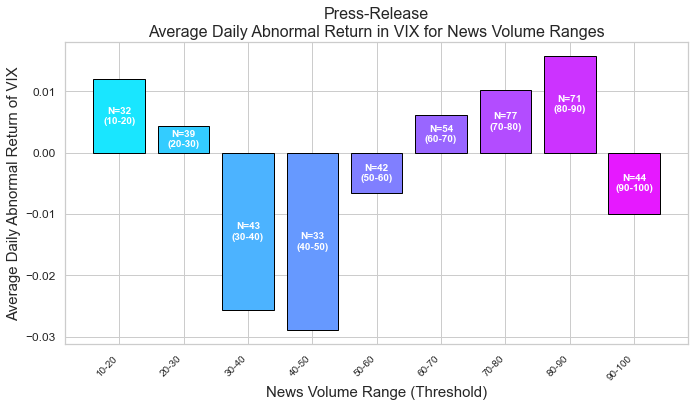

In [7]:
# Define the range start and end points
range_start = 10
range_end = 100
step_size = 10

# Calculate average returns for each range
threshold_ranges = [(start, start + step_size) for start in range(range_start, range_end, step_size)]
average_returns_ranges = [calculate_average_return_above_threshold(start, end) for start, end in threshold_ranges]
num_observations_ranges = [len(df[(df["NewsVolume"] >= start) & (df["NewsVolume"] < end)]) for start, end in threshold_ranges]

# Plotting
plt.figure(figsize=(10, 6))
sns.set_style("whitegrid")  # Set the plot style

# Customize the colors
colors = sns.color_palette("cool", len(average_returns_ranges))

# Create the bar plot
bars = plt.bar(range(len(average_returns_ranges)), average_returns_ranges, color=colors, edgecolor='black')

# Add labels for number of observations inside each bar
for i, bar in enumerate(bars):
    start, end = threshold_ranges[i]
    num_observations = num_observations_ranges[i]
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() / 2, f"N={num_observations}\n({start}-{end})", ha='center', va='center', fontsize=10, color='white', fontweight='bold')

# Customize font and fontsize
plt.xticks(range(len(average_returns_ranges)), [f"{start}-{end}" for start, end in threshold_ranges], rotation=45, ha='right', fontsize=10)
plt.yticks(fontsize=12)

# Set labels and title with improved font properties
plt.xlabel("News Volume Range (Threshold)", fontsize=15)
plt.ylabel("Average Daily Abnormal Return of VIX", fontsize=15)
plt.title("Press-Release\nAverage Daily Abnormal Return in VIX for News Volume Ranges", fontsize=16)

# Adjust spacing and display the plot
plt.tight_layout()
plt.show()

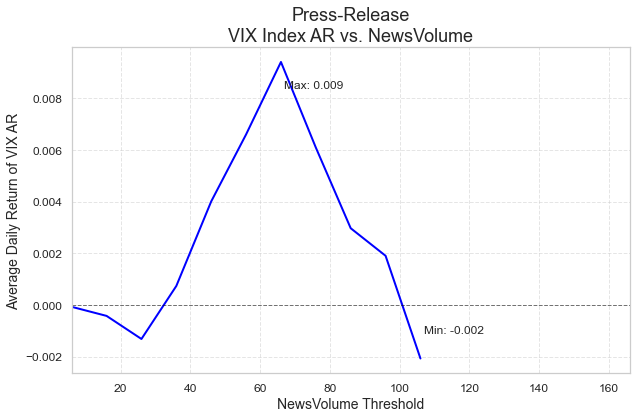

In [9]:
def calculate_average_return_above_threshold(threshold):
    news_above_threshold = df[df["NewsVolume"] > threshold]
    dates_above_threshold = pd.to_datetime(news_above_threshold.index).date
    vix_above_threshold = df[df.index.isin(dates_above_threshold)]
    return vix_above_threshold["VIX AR"].mean()


s_min = df["NewsVolume"].min()

thresholds = [ s_min, s_min+10, s_min+20, s_min+30, s_min+40, s_min+50,s_min+60,s_min+70,s_min+80,s_min+90,s_min+100,df["NewsVolume"].max()]
average_returns = [calculate_average_return_above_threshold(threshold) for threshold in thresholds]


# Create a figure with a size of 10 x 6 inches
fig, ax = plt.subplots(figsize=(10,6))

# Plot the data with a blue line
ax.plot(thresholds, average_returns, color='blue', linewidth=2)

# Set the x-axis and y-axis labels and title
ax.set_xlabel('NewsVolume Threshold', fontsize=14)
ax.set_ylabel('Average Daily Return of VIX AR', fontsize=14)
ax.set_title('Press-Release\nVIX Index AR vs. NewsVolume', fontsize=18)

# Add a grid to the plot
ax.grid(True, linestyle='--', alpha=0.5)

# Customize the tick labels and font size
ax.tick_params(axis='both', which='major', labelsize=12)

# Set the x-axis limits
ax.set_xlim([s_min,df["NewsVolume"].max()])

# Add a horizontal line at y=0 for reference
ax.axhline(y=0, color='black', linewidth=1, linestyle='--', alpha=0.5)

# Add text labels to highlight the maximum and minimum points
max_return = max(average_returns)
min_return = min(average_returns)
max_index = average_returns.index(max_return)
min_index = average_returns.index(min_return)
ax.text(thresholds[max_index]+1, max_return-0.001, f'Max: {max_return:.3f}', fontsize=12)
ax.text(thresholds[min_index]+1, min_return+0.001, f'Min: {min_return:.3f}', fontsize=12)

# Show the plot
plt.show()